# Room Reconstruction v2 — independent VGGT reconstruction

In VS Code, open this notebook and select **Select Kernel → Colab → New Colab Server**, choosing a GPU server.
Put `roomdelta3d_v2_colab_reviewed_20261015.zip` in **My Drive / Room Reconstruction v2** before running the first cell.
The first cell mounts Drive, copies the ZIP to local runtime storage, and verifies its contents.
It contains only the reconstruction code/configuration and the 32 Before + 30 After selected PNGs/model inputs.
No videos, Gemini credentials, VLM prompts, evaluation labels or model checkpoints are included.

Run cells in order. Pilot outputs are separate from full predictions. All coordinates remain relative, and successful inference does not establish real-scene accuracy.
The setup uses an isolated Python environment with pinned PyTorch/torchvision and a content-verified VGGT checkpoint.


In [1]:
import hashlib, json, shutil, subprocess, sys, zipfile
from pathlib import Path, PurePosixPath
from google.colab import drive
from IPython.display import display, Image as DisplayImage

EXPECTED_PROJECT_FILES = {'reconstruction_v2/archive.py': 'f7f77fd6257ea1e6450dd5222f637b489858da62d94c92a873a1aaeee30a2553', 'reconstruction_v2/core.py': '879ef864ce8b83c7c77ef2f6d79ee05b25b550b318ed0999d7df0dfdf5668bb6', 'reconstruction_v2/inference.py': 'a764dc3d60fd6e3d328cabdb7d48200a817d70fd9ec7ca1f41227ccc6f679463', 'reconstruction_v2/viewer.py': '4b80a7ddc330faeddd18f5610d953737f4240c44b8de48dd964602211259b927', 'reconstruction_v2/__init__.py': 'b5b5494be0edc90e8697bd20327f81e3fb15139c75eb994b359f45a880a122b2', 'scripts/reconstruct.py': '7aeb3fc678c25b9b7bfd3b7b5b7764fb9f05971fe006bfa563c960278ff65d96', 'scripts/setup_colab.py': 'efb1b39b26ec1c9b22cb38ce12b963e2cb5c95b514d250ae2f919a0b606103fc', 'scripts/colab_run.py': '26356bc432e0ac619ec5a31edcb07e45434d7dc36053a3ea09c29da94d874167', 'configs/reconstruction.json': '0baeedb6141d3d27918aae43b4b6733ddc134de9f961f5efbf71693fb826d8c1', 'configs/models.lock.json': '830ec392f44e7fd8a50fda04720a8e034550df093c184bb0ba5d9edb52745585', 'requirements-reconstruction.txt': 'c0c5c566772177b1238d7a00b6d65a7c850b72ff053c75cfc701d464a1f65f1a', 'reference/vggt_load_fn.py': 'd57b7a16c2e04333a2e68d365aa21f1dd61759e984f744cbcbe6b66d787f37ef'}

def verify_active_project():
    changed = []
    for relative, expected in EXPECTED_PROJECT_FILES.items():
        path = PROJECT / relative
        if not path.is_file():
            changed.append(relative)
            continue
        with path.open('rb') as handle:
            if hashlib.file_digest(handle, 'sha256').hexdigest() != expected:
                changed.append(relative)
    if changed:
        raise RuntimeError('Notebook/bundle code mismatch: ' + ', '.join(changed) +
                           '. Upload the ZIP paired with this notebook and extract it in a fresh runtime. '
                           'Read saved diagnostics before leaving the current runtime.')
    print('Active project matches this notebook:', len(EXPECTED_PROJECT_FILES), 'verified files')

# Edit this folder only if you put the ZIP elsewhere in My Drive.
DRIVE_FOLDER = Path('/content/drive/MyDrive/Room Reconstruction v2')
if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')  # Complete the extension's Google authorization prompt.
drive_bundle = DRIVE_FOLDER / 'roomdelta3d_v2_colab_reviewed_20261015.zip'
if not drive_bundle.is_file():
    raise FileNotFoundError(f'Put the prepared ZIP here, or edit DRIVE_FOLDER: {drive_bundle}')
BUNDLE_ROOT = Path('/content/roomdelta3d_v2_bundle')
if BUNDLE_ROOT.exists():
    raise RuntimeError('Bundle directory already exists. Reuse the subsequent cells on this runtime, or start a fresh runtime.')
bundle_path = Path('/content/roomdelta3d_v2_colab_ready.zip')
shutil.copyfile(drive_bundle, bundle_path)
BUNDLE_ROOT.mkdir()
with zipfile.ZipFile(bundle_path) as bundle:
    seen = set()
    for info in bundle.infolist():
        name = info.filename
        parts = PurePosixPath(name)
        if name in seen or parts.is_absolute() or '..' in parts.parts or '\\' in name or ':' in name:
            raise ValueError('Unsafe/duplicate bundle member')
        seen.add(name)
        if ((info.external_attr >> 16) & 0o170000) == 0o120000:
            raise ValueError('Symlink bundle member')
        if not info.is_dir():
            target = (BUNDLE_ROOT / name).resolve()
            if not target.is_relative_to(BUNDLE_ROOT):
                raise ValueError('Member escapes bundle root')
            target.parent.mkdir(parents=True, exist_ok=True)
            with bundle.open(info) as source, target.open('wb') as destination:
                shutil.copyfileobj(source, destination)
receipt = json.loads((BUNDLE_ROOT / 'bundle_receipt.json').read_text())
actual = {p.relative_to(BUNDLE_ROOT).as_posix() for p in BUNDLE_ROOT.rglob('*') if p.is_file()}
assert actual == set(receipt['files']) | {'bundle_receipt.json'}
for name, expected in receipt['files'].items():
    with (BUNDLE_ROOT / name).open('rb') as handle:
        assert hashlib.file_digest(handle, 'sha256').hexdigest() == expected, name
PROJECT = BUNDLE_ROOT / 'project'
WORKSPACE = Path('/content/roomdelta3d_v2_workspace')
RUN = WORKSPACE / 'reconstruction'
verify_active_project()
print('Verified Drive bundle:', drive_bundle, 'Files:', len(receipt['files']))


Mounted at /content/drive
Active project matches this notebook: 12 verified files
Verified Drive bundle: /content/drive/MyDrive/Room Reconstruction v2/roomdelta3d_v2_colab_reviewed_20261015.zip Files: 13


## Install pinned runtime and checkpoint
The checkpoint download is approximately 5 GB. This cell records package versions and verifies the checkpoint SHA-256.
The system Python/driver/GPU assignment is recorded rather than assumed reproducible by Colab.


In [2]:
import os
from collections import deque

def run_logged(command, label):
    # Pipe child output explicitly so VS Code receives it through notebook stdout.
    log_directory = WORKSPACE / 'logs'
    log_directory.mkdir(parents=True, exist_ok=True)
    log_path = log_directory / f'{label}.log'
    tail = deque(maxlen=60)
    print(f'{label}: starting; log: {log_path}', flush=True)
    with log_path.open('a', encoding='utf-8') as log:
        with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                              text=True, bufsize=1, env=dict(os.environ, PYTHONUNBUFFERED='1')) as process:
            for line in process.stdout:
                print(line, end='', flush=True)
                log.write(line)
                log.flush()
                tail.append(line)
            returncode = process.wait()
    if returncode:
        raise RuntimeError(f'{label} failed (exit {returncode}). Log: {log_path}\nLast output:\n' + ''.join(tail))
    print(f'{label}: completed', flush=True)

verify_active_project()
run_logged([sys.executable, str(PROJECT / 'scripts/setup_colab.py'), '--workspace', str(WORKSPACE)], 'setup')
PYTHON = str(WORKSPACE / 'venv/bin/python')
CLI = str(PROJECT / 'scripts/reconstruct.py')
if not RUN.exists():
    run_logged([PYTHON, CLI, 'import', '--archive', str(BUNDLE_ROOT / 'prepared_run.zip'), '--output', str(RUN)], 'import')
print('Prepared run:', RUN)


Active project matches this notebook: 12 verified files
setup: starting; log: /content/roomdelta3d_v2_workspace/logs/setup.log
Virtual environment has no pip; trying ensurepip
/content/roomdelta3d_v2_workspace/venv/bin/python: No module named ensurepip
ensurepip did not provide pip; using the official PyPA bootstrap in the virtual environment
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 7.4 MB/s  0:00:00
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 140.6 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 155.1 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 200.1 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 67.3 MB/s  0:00:11
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 69.5 MB/s  0:00:04
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 159.2 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Measured GPU pilots
Run 4, 8, then 16 representative frames per capture in fresh, separate workers.
Each worker checks the saved model tensors against the exact upstream loader before inference.
Attention is evaluated in bounded query slices while retaining all frame keys/values. Runtime records include this policy and memory measurements.
Inspect failures/logs instead of silently reducing frame count or resolution. A passed pilot does not guarantee the full run will fit.
If a pilot has already failed in this runtime, run the next diagnostic cell to inspect its saved worker exceptions without rerunning inference.


In [3]:
# Read-only diagnostics: safe to run after a failure, including with an older bundle.
from collections import deque

def show_pilot_diagnostics():
    def read_saved_json(path):
        try:
            return json.loads(path.read_text(encoding='utf-8'))
        except (OSError, ValueError) as error:
            print(f'Cannot read {path}: {error}')
            return {}

    report_path = RUN / 'pilot_report.json'
    report = read_saved_json(report_path) if report_path.is_file() else {}
    print('Saved pilot report:', report.get('status', 'not available'), report_path)
    pilots = report.get('pilots', [])
    if not pilots:
        # Workers may have failed before the parent wrote its report.
        pilots = [{'requested_frames': int(path.name[1:]), 'captures': {}}
                  for path in sorted((WORKSPACE / 'pilots').glob('p[0-9][0-9]'))]
    for pilot in pilots:
        count = pilot['requested_frames']
        target = WORKSPACE / 'pilots' / f'p{count:02d}'
        for capture in ('before', 'after'):
            measurement = pilot.get('captures', {}).get(capture, {})
            env_path = target / capture / 'inference_environment.json'
            env = measurement.get('environment') or (read_saved_json(env_path) if env_path.is_file() else {})
            status = measurement.get('status', env.get('status', 'unknown'))
            def gib(key):
                value = env.get(key)
                return round(value / 1024**3, 3) if value is not None else 'unavailable'
            print(count, capture, status, 'allocated GiB:', gib('cuda_peak_allocated_bytes'),
                  'reserved GiB:', gib('cuda_peak_reserved_bytes'), 'inference seconds:', env.get('inference_sec'))
            print('Stage:', env.get('stage', 'unknown'), 'attention:', env.get('attention', 'not recorded'))
            if status == 'completed':
                continue
            print('Worker error:', env.get('error') or measurement.get('worker_error')
                  or measurement.get('error') or 'No structured worker error; inspect log below.')
            log_path = target / 'logs' / f'{capture}.log'
            print('Worker log:', log_path)
            try:
                with log_path.open(encoding='utf-8', errors='replace') as handle:
                    tail = ''.join(deque(handle, maxlen=60))
            except OSError as error:
                tail = measurement.get('worker_log_tail') or f'Worker log unavailable: {error}'
            print(tail or '(empty worker log)')

show_pilot_diagnostics()


Saved pilot report: not available /content/roomdelta3d_v2_workspace/reconstruction/pilot_report.json


Active project matches this notebook: 12 verified files
pilot: starting; log: /content/roomdelta3d_v2_workspace/logs/pilot.log
before: fresh GPU worker (4 frames)
after: fresh GPU worker (4 frames)
4-frame pilot: both independent captures completed
before: fresh GPU worker (8 frames)
after: fresh GPU worker (8 frames)
8-frame pilot: both independent captures completed
before: fresh GPU worker (16 frames)
after: fresh GPU worker (16 frames)
16-frame pilot: both independent captures completed
{
  "pilot_status": "passed",
  "sizes": [
    4,
    8,
    16
  ]
}
pilot: completed
Saved pilot report: passed /content/roomdelta3d_v2_workspace/reconstruction/pilot_report.json
4 before completed allocated GiB: 6.857 reserved GiB: 8.461 inference seconds: 4.916676429999939
Stage: completed attention: {'implementation': 'bounded_query_sdpa', 'query_chunk_size': 512, 'chunked_calls': 72, 'native_calls': 16, 'max_query_tokens': 3128, 'max_key_tokens': 3128, 'max_chunk_query_tokens': 512, 'key_value

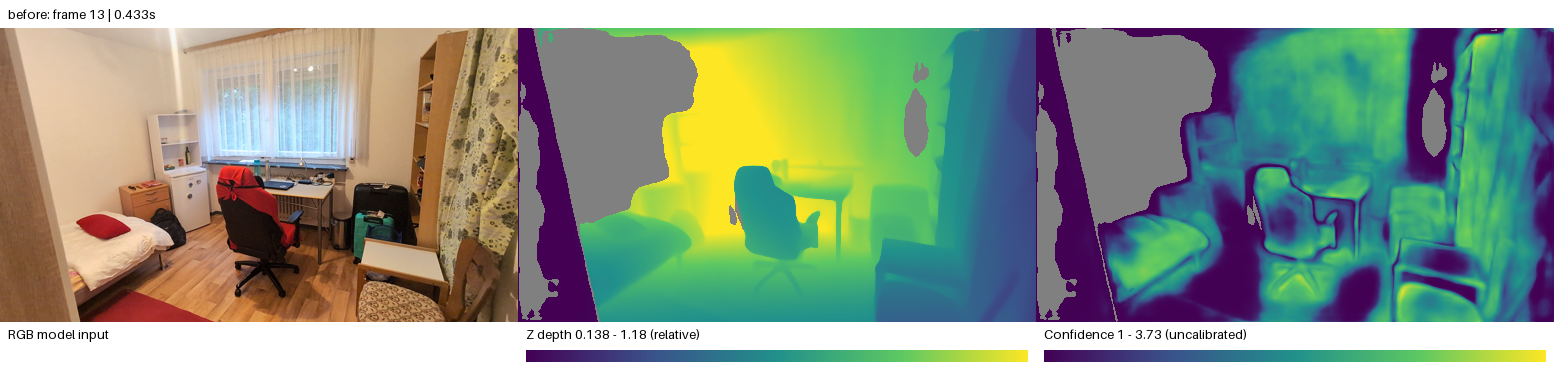

after actual 4-frame pilot prediction; independent pilot coordinate/scale frame


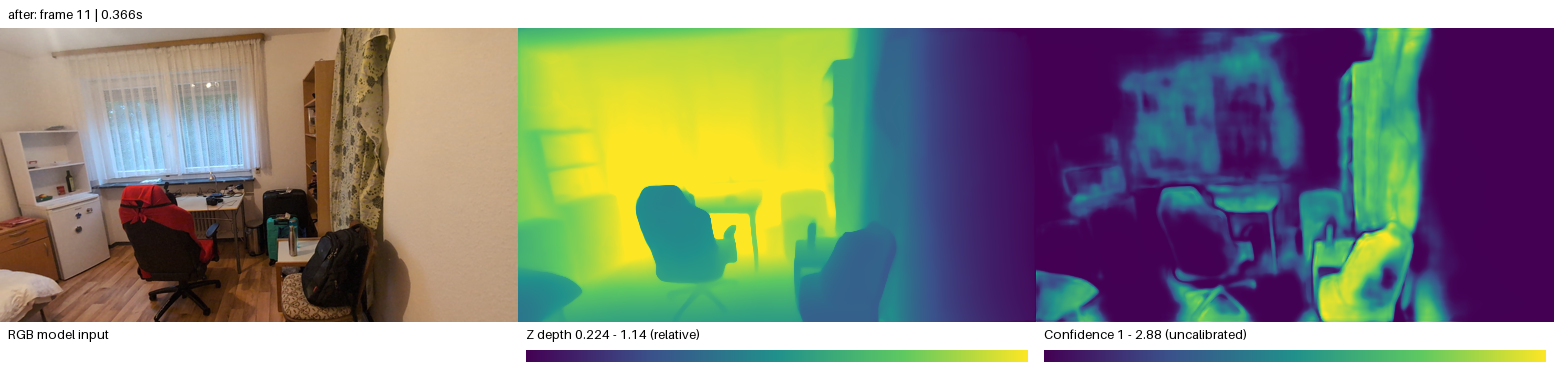

In [4]:
verify_active_project()
try:
    run_logged([PYTHON, str(PROJECT / 'scripts/colab_run.py'), '--run', str(RUN), '--workspace', str(WORKSPACE), '--phase', 'pilot'], 'pilot')
finally:
    show_pilot_diagnostics()
for name in ('before', 'after'):
    panels = sorted((WORKSPACE / 'pilots/p04' / name / 'previews').glob('*_panel.png'))
    if panels:
        print(name, 'actual 4-frame pilot prediction; independent pilot coordinate/scale frame')
        display(DisplayImage(filename=str(panels[0]), width=1100))
    else:
        print(name, '4-frame pilot preview unavailable; inspect worker diagnostics above.')


## Full independent predictions
Process all 32 Before and 30 After selected frames separately. Save depth/confidence/masks, cameras, colored PLY/numerical clouds, all point observations, and quality reports.
`--resume` reuses only hash-compatible, structurally verified captures. Never use pilot geometry as full-run geometry.


Active project matches this notebook: 12 verified files
full: starting; log: /content/roomdelta3d_v2_workspace/logs/full.log
before: fresh GPU worker (32 frames)
after: fresh GPU worker (30 frames)
Both independent captures completed. Geometric accuracy still requires visual review.
full: completed
verify: starting; log: /content/roomdelta3d_v2_workspace/logs/verify.log
{
  "status": "verified",
  "output": "/content/roomdelta3d_v2_workspace/reconstruction",
  "result": {
    "before": {
      "internal_consistency": "passed",
      "cloud_points": 2848388,
      "observations": 4873344,
      "sampled_self_reprojections": 5000,
      "max_self_reprojection_error_model_pixels": 3.410605131648481e-13,
      "max_original_pixel_mapping_error": 6.079949935156037e-05,
      "max_sampled_cloud_reprojection_error_model_pixels": 9.248199125799772e-05,
      "point_color_source_verified": true,
      "all_points_have_observations": true,
      "units": "relative",
      "coordinate_frame": "be

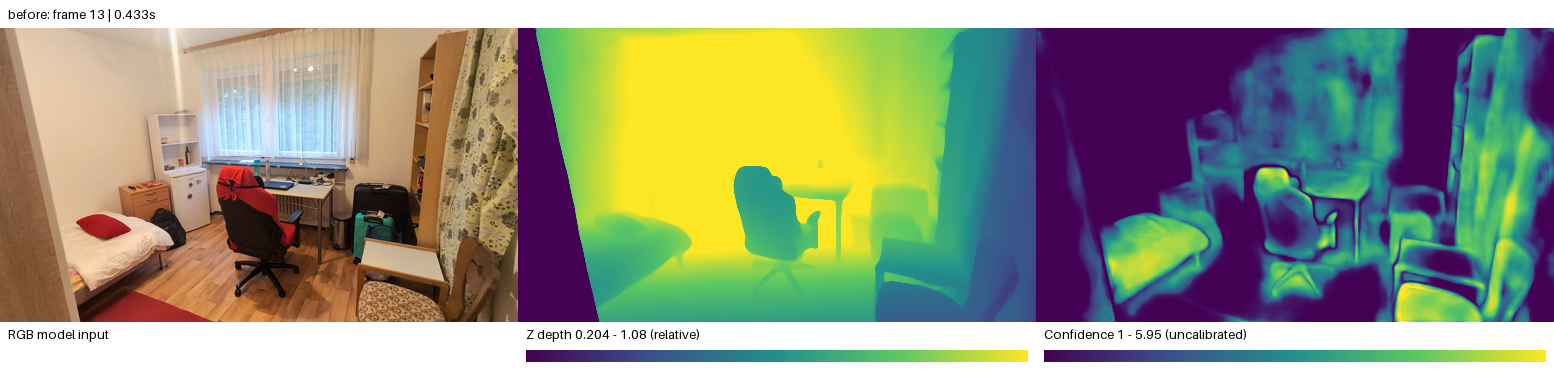

after points: 2652094 internal consistency: passed real-scene accuracy: not_independently_validated


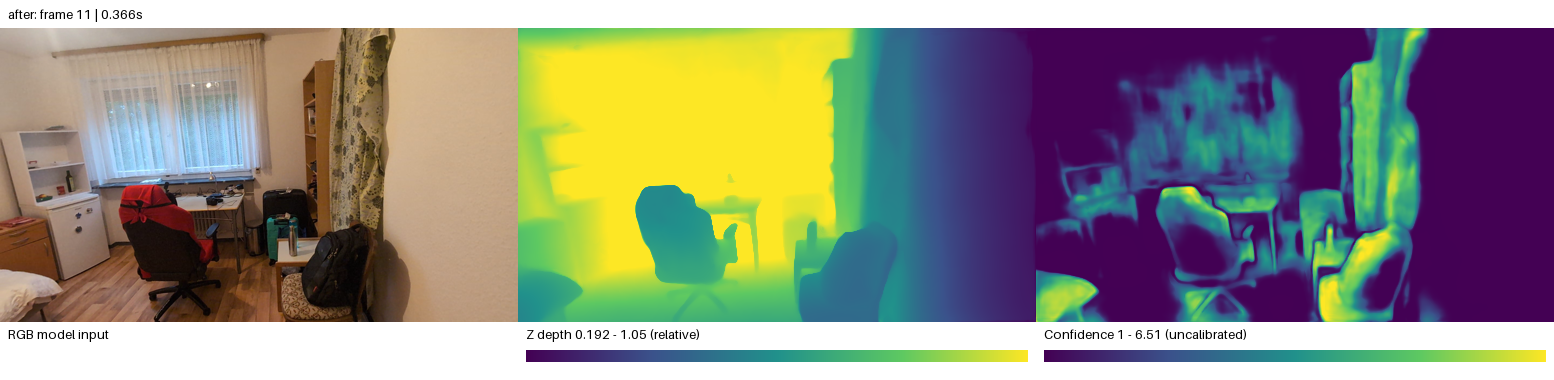

In [5]:
verify_active_project()
run_logged([PYTHON, str(PROJECT / 'scripts/colab_run.py'), '--run', str(RUN), '--workspace', str(WORKSPACE), '--phase', 'full'], 'full')
run_logged([PYTHON, CLI, 'verify', '--run', str(RUN)], 'verify')
for name in ('before', 'after'):
    report = json.loads((RUN / name / 'quality_report.json').read_text())
    print(name, 'points:', report['cloud_points'], 'internal consistency:', report['internal_consistency'],
          'real-scene accuracy:', report['real_scene_accuracy'])
    panels = sorted((RUN / name / 'previews').glob('*_panel.png'))
    display(DisplayImage(filename=str(panels[0]), width=1100))


## Save portable results to Drive
The ZIP contains source/model images, depth arrays, camera records, cloud/provenance and reports; it excludes the checkpoint and environment installation.
This cell copies the completed archive directly beside the input ZIP in Drive and verifies its SHA-256 after copying.
Download that ZIP from Drive, import it locally using `scripts/reconstruct.py import`, then run `verify`, `preview`, or `view`.
Drive persistence occurs after this cell finishes; interrupted inference stays in the current runtime until explicitly saved.


In [6]:
RESULTS = WORKSPACE / 'roomdelta3d_v2_reconstruction.zip'
if RESULTS.exists():
    raise RuntimeError('Results archive already exists; choose a new RESULTS filename to preserve it.')
run_logged([PYTHON, CLI, 'pack', '--run', str(RUN), '--archive', str(RESULTS)], 'pack')
if not Path('/content/drive/MyDrive').is_dir():
    raise RuntimeError('Drive is no longer mounted; remount it before copying the local results archive.')
saved_directory = DRIVE_FOLDER
saved_archive = saved_directory / RESULTS.name
staging_archive = saved_archive.with_suffix('.zip.partial')
receipt_path = saved_archive.with_suffix('.receipt.json')
if any(path.exists() for path in (saved_archive, staging_archive, receipt_path)):
    raise RuntimeError(f'Drive result or receipt already exists; choose a new RESULTS filename to preserve it: {saved_archive}')
shutil.copyfile(RESULTS, staging_archive)
with RESULTS.open('rb') as handle:
    expected = hashlib.file_digest(handle, 'sha256').hexdigest()
with staging_archive.open('rb') as handle:
    actual = hashlib.file_digest(handle, 'sha256').hexdigest()
if actual != expected:
    raise RuntimeError('Drive copy failed SHA-256 verification; local results remain available.')
staging_archive.rename(saved_archive)
save_receipt = {'archive': str(saved_archive), 'sha256': actual, 'bytes': saved_archive.stat().st_size}
receipt_path.write_text(json.dumps(save_receipt, indent=2) + '\n')
print('Saved verified results to Drive:', saved_archive)
print('SHA-256:', actual)


pack: starting; log: /content/roomdelta3d_v2_workspace/logs/pack.log
{
  "status": "verified",
  "output": "/content/roomdelta3d_v2_workspace/reconstruction",
  "result": {
    "path": "/content/roomdelta3d_v2_workspace/roomdelta3d_v2_reconstruction.zip",
    "sha256": "9cff5b2b3e760f9cd6f904a620bd4e663cffce186bdca878dabcdb5bc2530e5a",
    "bytes": 473039050
  }
}
pack: completed
Saved verified results to Drive: /content/drive/MyDrive/Room Reconstruction v2/roomdelta3d_v2_reconstruction.zip
SHA-256: 9cff5b2b3e760f9cd6f904a620bd4e663cffce186bdca878dabcdb5bc2530e5a
